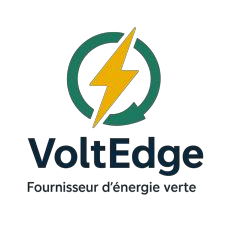

<h1 style="text-align:center;">Prédire le churn des clients dans le secteur de l'énergie</h1>

<h2 style="text-align:center;">Identifier les clients à risque</h1>

### 1_Importation des bibliothèques et chargement du dataset

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

In [74]:
df = pd.read_excel(r"C:\Users\sefas\Documents\Projets\Projet_Churn_VoltEdge\clients_voltedge.xlsx")
df.head()

,Age,AncienneteMois,ConsommationAnnuelle,FacturesImpayeDernierAn,Churn
0,56,26,13485,0,1
1,69,85,14056,0,1
2,46,86,7194,0,0
3,32,7,5909,0,1
4,60,14,5715,0,0


### 2_Traitement et analyses des données 

In [111]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   Age                      2000 non-null   int64   
 1   AncienneteMois           2000 non-null   int64   
 2   ConsommationAnnuelle     2000 non-null   int64   
 3   FacturesImpayeDernierAn  2000 non-null   int64   
 4   Churn                    2000 non-null   category
dtypes: category(1), int64(4)
memory usage: 64.7 KB


### Présentation du dataset
Le jeu de données contient 2000 observations et 5 variables, toutes complètes (**aucune valeur manquante**).
Les colonnes décrivent des caractéristiques clients :
*Age* : âge du client (entier).

*AncienneteMois* : durée de relation avec l’entreprise en mois.

*ConsommationAnnuelle* : consommation énergétique annuelle en kWh.

*FacturesImpayeDernierAn* : nombre d’impayés sur les 12 derniers mois.

*Churn* : variable cible indiquant si le client a quitté l’entreprise (catégorie 0/1).

- #### Ce dataset est propre, structuré et prêt pour l’analyse prédictive du churn.

In [109]:
# Conversion du type de la colonne "Churn"
df['Churn'] = df['Churn'].astype('category')

### 3_Analyse exploratoire

In [80]:
df.describe().round(2)

,Age,AncienneteMois,ConsommationAnnuelle,FacturesImpayeDernierAn
count,2000.00,2000.00,2000.00,2000.00
mean,49.66,59.69,8085.17,0.66
std,18.26,35.09,3006.10,1.05
min,18.00,1.00,1000.00,0.00
25%,34.00,29.00,6045.00,0.00
50%,50.00,60.00,8107.50,0.00
75%,66.00,90.00,10117.00,1.00
max,80.00,120.00,17781.00,6.00


#### Synthèse exploratoire des variables numériques
    Âge : une moyenne d’environ 50 ans avec une forte dispersion indique une clientèle très variée, allant de jeunes adultes à des seniors, ce qui peut créer des comportements de churn différents selon les segments.

    Ancienneté : une moyenne de 60 mois mais une grande variabilité (1 à 120 mois) révèle deux groupes distincts : des clients récents plus volatils et des clients fidèles installés depuis longtemps.

    Consommation annuelle : une moyenne autour de 8 000 kWh avec une large amplitude suggère des profils énergétiques très différents, les gros consommateurs pouvant représenter un segment stratégique.

    Factures impayées : la majorité des clients n’ont aucun impayé, mais une minorité présente jusqu’à 6 impayés, ce qui constitue un signal fort de risque ou d’instabilité.

#### Synthèse du Churn

In [90]:
df['Churn'].value_counts()

Churn
0    1200
1     800
Name: count, dtype: int64

In [115]:
X = [['Age', 'AncienneteMois', 'ConsommationAnnuelle', 'FacturesImpayeDernierAn']]
y = ['Churn']

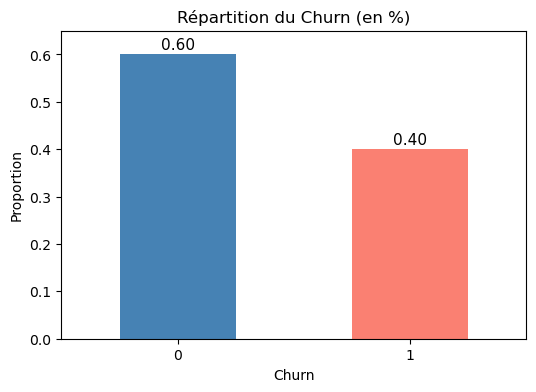

In [103]:
import matplotlib.pyplot as plt
counts = df['Churn'].value_counts(normalize=True)
plt.figure(figsize=(6,4))
bars = counts.plot(kind='bar', color=['steelblue', 'salmon'])
plt.title("Répartition du Churn (en %)")
plt.xlabel("Churn")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
# Ajout des étiquettes
for i, value in enumerate(counts):
    plt.text(i, value + 0.01, f"{value:.2f}", ha='center', fontsize=11)
plt.ylim(0, counts.max() + 0.05)
plt.show()

### La répartition du churn 
montre 1200 clients non‑churn (60 %) et 800 churn (40 %), ce qui indique un dataset modérément déséquilibré. La part de churn reste élevée, ce qui en fait un enjeu métier important pour la rétention. Cette proportion de 40 % implique que près d’un client sur deux est susceptible de partir, rendant la détection précoce essentielle. Une telle distribution justifie l’usage de modèles capables de bien capter les churners sans trop de faux négatifs.

### 4_Préparation des données

In [121]:
clients=df

In [125]:
clients.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   Age                      2000 non-null   int64   
 1   AncienneteMois           2000 non-null   int64   
 2   ConsommationAnnuelle     2000 non-null   int64   
 3   FacturesImpayeDernierAn  2000 non-null   int64   
 4   Churn                    2000 non-null   category
dtypes: category(1), int64(4)
memory usage: 64.7 KB


In [127]:
X = clients[['Age', 'AncienneteMois', 'ConsommationAnnuelle', 'FacturesImpayeDernierAn']]
y = clients['Churn']

In [129]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### 5_Modèle Logistique de Regression

In [131]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [133]:
predictions = model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)
print(f"Précision du modèle : {accuracy * 100:.2f}%")
conf_matrix = confusion_matrix(y_test, predictions)
print("Matrice de confusion :")
print(conf_matrix)

Précision du modèle : 82.75%
Matrice de confusion :
[[215  30]
 [ 39 116]]


###  Evaluations des résultats

**Précision globale** du modèle : **82,75 %**
    
- Cela signifie que le modèle fait une prédiction correcte pour **environ 8 clients sur 10** sur l'ensemble test.

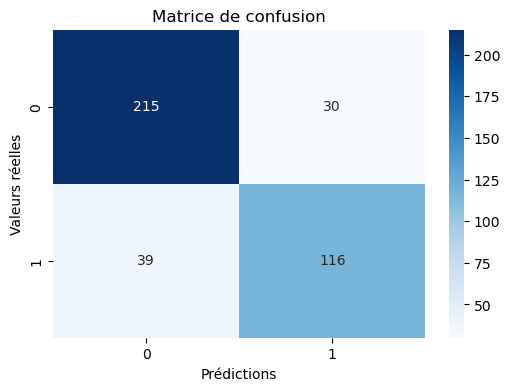

In [135]:
# Matrice de confusion
conf_matrix = confusion_matrix(y_test, predictions)
plt.figure(figsize=(6,4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Matrice de confusion")
plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")
plt.show()

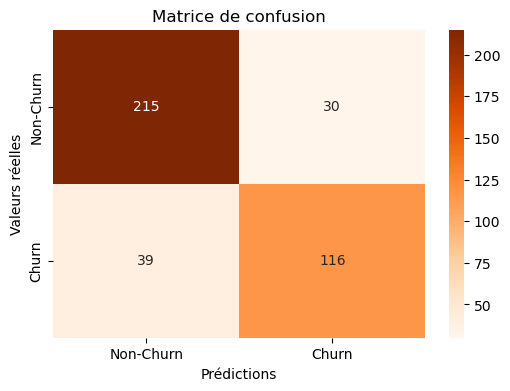

In [137]:
labels = ["Non-Churn", "Churn"]
plt.figure(figsize=(6,4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Oranges',
            xticklabels=labels, yticklabels=labels)
plt.title("Matrice de confusion")
plt.xlabel("Prédictions")
plt.ylabel("Valeurs réelles")
plt.show()

###  Matrice de confusion
La matrice montre que le modèle identifie bien les non‑churn (**215 vrais négatifs**) mais confond encore une partie des churners. Les **faux positifs (30)** restent modérés, ce qui limite les alertes inutiles. Les **faux négatifs (39)** sont plus problématiques, car ce sont des clients churn réels que le modèle ne détecte pas. Les **vrais positifs (116)** indiquent une capacité correcte à repérer les clients à risque. 
- #### Globalement, le modèle est performant mais peut être amélioré pour réduire les faux négatifs.

### 6_Fonction de prédiction

In [147]:
def predict_churn(age, anciennete_mois, consommation_annuelle, factures_impaye):
    # Création du dataFrame
    features = pd.DataFrame({
        'Age': [age],
        'AncienneteMois': [anciennete_mois],
        'ConsommationAnnuelle': [consommation_annuelle],
        'FacturesImpayeDernierAn': [factures_impaye]
    })
    
    # Prédir la probabilité
    proba_churn = model.predict_proba(features)[0][1]
    
    return f"Probabilité de churn : {proba_churn * 100:.2f}%"

In [173]:
# Exemples, age  40, Anciennté 7, Consommation 15000, Factures impayées 0
predict_churn(40, 7, 15000, 0)

'Probabilité de churn : 83.48%'

In [175]:
# Exemples, age  40, Anciennté 7, Consommation 15000, Factures impayées 2
predict_churn(40, 7, 15000, 2)

'Probabilité de churn : 99.06%'

### 7_Application sur de nouveaux clients

In [189]:
new_clients = pd.read_excel(r"C:\Users\sefas\Documents\Projets\Projet_Churn_VoltEdge\new_clients_voltedge.xlsx")
probas_churn = model.predict_proba(new_clients[['Age', 'AncienneteMois', 'ConsommationAnnuelle', 'FacturesImpayeDernierAn']])[:, 1]
new_clients['ProbabiliteChurn'] = probas_churn
new_clients.head()

,Age,AncienneteMois,ConsommationAnnuelle,FacturesImpayeDernierAn,ProbabiliteChurn
0,63,49,1000,1,0.102776
1,67,42,10010,0,0.154053
2,20,27,10956,1,0.950996
3,79,39,3242,1,0.085544
4,39,83,8529,1,0.573658


In [201]:
# Enregistrement dans un nouveau fichier Excel 
output_path = r"C:\Users\sefas\Documents\Projets\Projet_Churn_VoltEdge\new_clients_churn_scores.xlsx"
new_clients.to_excel(output_path, index=False)
print("Fichier enregistré avec succès :", output_path)

Fichier enregistré avec succès : C:\Users\sefas\Documents\Projets\Projet_Churn_VoltEdge\new_clients_churn_scores.xlsx


### 8_Autres métriques : **Recall**, **Precision**, **F1-Score**

In [267]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
f1 = f1_score(y_test, predictions)

print(f"Précision :        {precision * 100:.2f}%")
print(f"Rappel (Recall) :  {recall * 100:.2f}%")
print(f"F1-Score :         {f1 * 100:.2f}%")

Précision :        79.45%
Rappel (Recall) :  74.84%
F1-Score :         77.08%


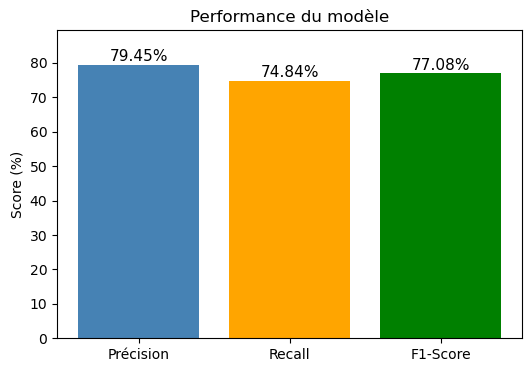

In [207]:
# Valeurs des métriques
metrics = {
    "Précision": precision * 100,
    "Recall": recall * 100,
    "F1-Score": f1 * 100
}
plt.figure(figsize=(6,4))
plt.bar(metrics.keys(), metrics.values(), color=["steelblue", "orange", "green"])

# Ajout des étiquettes sur les barres
for i, value in enumerate(metrics.values()):
    plt.text(i, value + 1, f"{value:.2f}%", ha='center', fontsize=11)
plt.ylim(0, max(metrics.values()) + 10)
plt.title("Performance du modèle")
plt.ylabel("Score (%)")
plt.show()

### Interprétation des métriques

    La précision est la plus élevée (79.45 %), ce qui indique peu de faux positifs.

    Le recall est légèrement plus bas (~74.84 %), montrant que certains churners ne sont pas détectés.

    Le F1‑Score (77.08 %) équilibre les deux et donne une vision globale de la qualité du modèle.

### 9_Modèle : Forêt aléatoire (Random Forest)

In [210]:
from sklearn.ensemble import RandomForestClassifier

Précision globale :              96.00%
Precision (précision positive) : 91.12%
Recall (rappel des churns) :     99.35%
F1-Score :                       95.06%


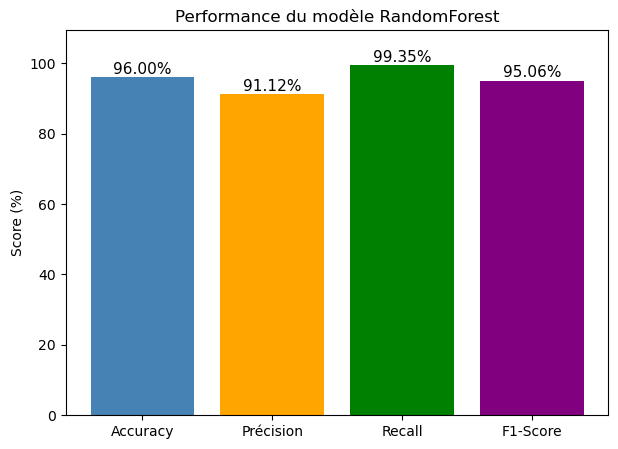

In [265]:
# Création du modèle
rf_model = RandomForestClassifier(random_state=42)
# Entraînement
rf_model.fit(X_train, y_train)
# Prédictions
rf_predictions = rf_model.predict(X_test)
# Évaluation
rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_precision = precision_score(y_test, rf_predictions)
rf_recall = recall_score(y_test, rf_predictions)
rf_f1 = f1_score(y_test, rf_predictions)
# Affichage des résultats numériques
print(f"Précision globale :              {rf_accuracy * 100:.2f}%")
print(f"Precision (précision positive) : {rf_precision * 100:.2f}%")
print(f"Recall (rappel des churns) :     {rf_recall * 100:.2f}%")
print(f"F1-Score :                       {rf_f1 * 100:.2f}%")
# -----------------------------
# Représentation graphique
# -----------------------------
metrics_names = ["Accuracy", "Précision", "Recall", "F1-Score"]
metrics_values = [
    rf_accuracy * 100,
    rf_precision * 100,
    rf_recall * 100,
    rf_f1 * 100
]

plt.figure(figsize=(7,5))
bars = plt.bar(metrics_names, metrics_values, color=["steelblue", "orange", "green", "purple"])

# Ajout des étiquettes sur les barres
for i, value in enumerate(metrics_values):
    plt.text(i, value + 1, f"{value:.2f}%", ha='center', fontsize=11)

plt.ylim(0, max(metrics_values) + 10)
plt.title("Performance du modèle RandomForest")
plt.ylabel("Score (%)")
plt.show()

## Résultats du modèle RandomForestClassifier :
    Le modèle RandomForest montre une excellente performance globale, avec une accuracy de 96 %, ce qui traduit une forte capacité à prédire correctement churn et non‑churn. 
    La précision à 91 % indique que la majorité des clients prédits comme churn le sont réellement, limitant les fausses alertes. 
    Le recall très élevé (99 %) montre que le modèle détecte presque tous les churners, ce qui est crucial pour une stratégie de rétention. 
    Le F1‑Score à 95 % confirme un bon équilibre entre précision et rappel. 
    
### L’ensemble suggère un modèle robuste, particulièrement efficace pour identifier les clients à risque.

## Le modèle offre une capacité solide à identifier les clients à risque, ce qui permet d’anticiper efficacement le churn. Le rappel très élevé montre qu’une grande majorité des clients susceptibles de partir sont correctement détectés. Ces résultats ouvrent la voie à des actions ciblées comme des offres personnalisées ou un suivi prioritaire. L’enjeu métier est désormais d’intégrer ces scores dans les processus CRM pour maximiser la rétention.